In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mikeio
from mikeio import Grid1D

# 可选：更精确的大地测距/沿大圆布点
try:
    from pyproj import Geod
    HAS_PYPROJ = True
except Exception:
    HAS_PYPROJ = False
    Geod = None

# 2D Salinity

In [ ]:
# ========= 输入 =========
in_dfs2 = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\salinity_depthmean.dfs2"          # TODO: 你的源 dfs2（同一个）
out_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc"       # TODO: 输出文件夹（会自动生成文件名）

# ========= spacing 全部一样 =========
spacing_m = 5000.0                  # TODO: 所有边界统一间隔（米）

# ========= 5 个边界（只填坐标 + 名称）=========
# direction = start -> end （方向性由你填的顺序决定）
boundaries = [
    {"name": "N", "start": (122.493443776622, 26.5692367496994), "end": (120.645694717, 27.3650832700001)},
    {"name": "NE", "start": (121.923074083, 25.1295883820001),      "end": (122.493443776622, 26.5692367496994)},
    {"name": "E", "start": (120.88891665278, 20.8980460556474),      "end": (120.860675479, 21.894682034)},
    {"name": "S", "start": (117.956262923109, 20.5681108483984),      "end": (120.88891665278, 20.8980460556474)},
    {"name": "SW", "start": (116.499393628, 22.9394535060001),      "end": (117.956262923109, 20.5681108483984)},
]

# ========= QC 只做一次，用哪个边界做 QC =========
qc_boundary_index = 0              # 默认用 N 做 QC（也可以改成 2/3/4/5）

# ========= 用哪个 item 做 QC（推荐用最敏感的那个）=========
qc_item_name = None  # TODO: 改成你的 item 名称；None 表示第一个 item

# ========= QC 阈值（按你的图：横向异常带 + 端点尖刺）=========
phys_min, phys_max = 0.0, 45.0     # 盐度示例（按变量改）
nan_frac_thr     = 0.30
end_spike_thr    = 3.0
global_drop_thr  = 3.0
rolling_win      = 11

# ========= 修复设置 =========
fill_edges_with_nearest = True     # 时间轴两端：用最近有效值补（ffill/bfill）

# ========= 空间最近湿点搜索半径（单位：格点数）=========
# 0.04/0.08°网格，建议从 3~5 起步；两列空值通常 3 就够
max_radius_cells = 4

# ========= 插值修复设置 =========
extrapolate_space = False          # 空间外推：建议 False（超出网格给 NaN）
fill_edges_with_nearest = True     # 开头/结尾若坏：用最近好值填（bfill/ffill）

# ========= 输出：坏时间步清单 =========
bad_csv = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\bad_timesteps.csv"

# ========= Visual check 画图用哪个 item =========
plot_item_name = qc_item_name


os.makedirs(out_dir, exist_ok=True)

ds2 = mikeio.read(in_dfs2)  # 只读一次
print(ds2)
print("projection:", ds2.geometry.projection)
print("mikeio version:", getattr(mikeio, "__version__", "unknown"))
print("pyproj available:", HAS_PYPROJ)


<mikeio.Dataset>
dims: (time:2920, y:177, x:89)
time: 2025-01-01 12:00:00 - 2026-01-01 09:00:00 (2920 records)
geometry: Grid2D (ny=177, nx=89)
items:
  0:  salinity_depthmean <Salinity> (PSU)
projection: LONG/LAT
mikeio version: 3.0.1
pyproj available: True


In [3]:
def pick_item(ds, item_name):
    if item_name is None:
        return ds[0]
    names = [it.name for it in ds.items]
    if item_name in names:
        return ds[item_name]
    hits = [n for n in names if item_name.lower() in n.lower()]
    if not hits:
        raise ValueError(f"cannot find item={item_name}, items={names}")
    print("item_name not exact, using:", hits[0])
    return ds[hits[0]]

def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371000.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlmb = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlmb/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def build_transect_points(start, end, spacing_m):
    lon0, lat0 = start
    lon1, lat1 = end

    if HAS_PYPROJ:
        geod = Geod(ellps="WGS84")
        az12, az21, dist = geod.inv(lon0, lat0, lon1, lat1)
        nseg = max(int(np.floor(dist/spacing_m)), 1)
        npts = nseg + 1
        mids = geod.npts(lon0, lat0, lon1, lat1, npts-2)
        lons = np.array([lon0] + [p[0] for p in mids] + [lon1], dtype=float)
        lats = np.array([lat0] + [p[1] for p in mids] + [lat1], dtype=float)
        chain = np.zeros(npts, dtype=float)
        for i in range(1, npts):
            _, _, d = geod.inv(lons[i-1], lats[i-1], lons[i], lats[i])
            chain[i] = chain[i-1] + d
        return lons, lats, chain
    else:
        dist = haversine_m(lon0, lat0, lon1, lat1)
        nseg = max(int(np.floor(dist/spacing_m)), 1)
        npts = nseg + 1
        lons = np.linspace(lon0, lon1, npts)
        lats = np.linspace(lat0, lat1, npts)
        chain = np.linspace(0.0, dist, npts)
        return lons, lats, chain

# -------- 关键：wet_score（0~1）--------
def compute_wet_score(ds2, ref_item_name=None):
    """
    wet_score[y,x] = 该格点在全时间范围内为有限值的比例
    """
    da = pick_item(ds2, ref_item_name) if ref_item_name is not None else ds2[0]
    A = da.to_numpy()  # (time, y, x)
    wet_score = np.mean(np.isfinite(A), axis=0)  # (y, x)
    return wet_score

In [ ]:
def nearest_index(arr, val):
    return int(np.argmin(np.abs(arr - val)))

def map_point_to_best_cell(ds2, wet_score, lon, lat, max_radius_cells=4):
    """
    返回 (iy, ix, snapped_flag)
    策略：在邻域内优先选择 wet_score 最大的格点；
         若多个格点 wet_score 相同，则选距离最近的。
    """
    g = ds2.geometry
    xg = np.asarray(g.x)  # (nx,)
    yg = np.asarray(g.y)  # (ny,)

    ny, nx = wet_score.shape
    ix0 = nearest_index(xg, lon)
    iy0 = nearest_index(yg, lat)

    # 搜索窗口
    best = None
    best_score = -1.0
    best_d2 = None

    for r in range(0, max_radius_cells + 1):
        i0 = max(0, iy0 - r); i1 = min(ny - 1, iy0 + r)
        j0 = max(0, ix0 - r); j1 = min(nx - 1, ix0 + r)

        # 找窗口内 wet_score>0 的格点（至少某些时间有值）
        sub = wet_score[i0:i1+1, j0:j1+1]
        ys, xs = np.where(sub > 0.0)
        if len(xs) == 0:
            continue

        ys = ys + i0
        xs = xs + j0

        # 先比 wet_score，再比距离
        for iy, ix in zip(ys, xs):
            sc = wet_score[iy, ix]
            dx = xg[ix] - lon
            dy = yg[iy] - lat
            d2 = dx*dx + dy*dy
            if (sc > best_score) or (sc == best_score and (best_d2 is None or d2 < best_d2)):
                best = (iy, ix)
                best_score = sc
                best_d2 = d2

        # 若已经找到 score 很高的格点，可提前停止（可选）
        if best_score >= 0.99:
            break

    if best is None:
        return iy0, ix0, False
    else:
        return best[0], best[1], True

def extract_transect_nearestcell(ds2, start, end, spacing_m, wet_score, max_radius_cells=4):
    """
    输出：
      ds_tx: dfs1-like Dataset (time, x)（x 是 chainage）
      pts_df: 点位对照（原始 lon/lat，吸附后 lon/lat，wet_score）
    """
    g = ds2.geometry
    xg = np.asarray(g.x)
    yg = np.asarray(g.y)

    lons, lats, chain_m = build_transect_points(start, end, spacing_m)

    # 对每个采样点找最佳格点
    mapped = []
    for lon, lat in zip(lons, lats):
        iy, ix, snapped = map_point_to_best_cell(ds2, wet_score, lon, lat, max_radius_cells=max_radius_cells)
        mapped.append((iy, ix, snapped))

    mapped = np.array(mapped, dtype=object)
    iys = mapped[:,0].astype(int)
    ixs = mapped[:,1].astype(int)
    snapped_flags = mapped[:,2].astype(bool)

    # 记录对照表（很重要，便于看是否“挪点”）
    pts_df = pd.DataFrame({
        "distance_m": chain_m,
        "lon_in": lons,
        "lat_in": lats,
        "lon_used": xg[ixs],
        "lat_used": yg[iys],
        "snapped": snapped_flags,
        "wet_score_used": wet_score[iys, ixs]
    })

    # 逐 item 提取：直接取格点序列（避免插值 NaN）
    arrays = []
    for it, item in enumerate(ds2.items):
        da = ds2[it]                 # dims: (time, y, x)
        A = da.to_numpy()            # (time, ny, nx)
        data_tx = A[:, iys, ixs]     # (time, npts) —— 高效索引

        g1 = Grid1D(x=chain_m)
        da1 = mikeio.DataArray(
            data=data_tx,
            time=ds2.time,
            geometry=g1,
            item=item,
        )
        arrays.append(da1)

    ds_tx = mikeio.Dataset(arrays)
    return ds_tx, pts_df


In [7]:
wet_score = compute_wet_score(ds2, qc_item_name)

qc_bnd = boundaries[qc_boundary_index]
ds_qc, pts_qc = extract_transect_nearestcell(
    ds2, qc_bnd["start"], qc_bnd["end"], spacing_m, wet_score, max_radius_cells=max_radius_cells
)

# ---- QC 指标（和你之前一致）----
da_qc = pick_item(ds_qc, qc_item_name)
A = da_qc.to_numpy()                    # (time, x)
t = pd.DatetimeIndex(ds_qc.time)
A_nan = np.where(np.isfinite(A), A, np.nan)

nan_frac = np.mean(~np.isfinite(A), axis=1)
oor = (A_nan < phys_min) | (A_nan > phys_max)
oor_frac = np.mean(oor & np.isfinite(A_nan), axis=1)

min_x = np.nanmin(A_nan, axis=1)
max_x = np.nanmax(A_nan, axis=1)
med_x = np.nanmedian(A_nan, axis=1)

start = A_nan[:, 0]
end   = A_nan[:, -1]
start_drop = med_x - start
end_drop   = med_x - end

med_series = pd.Series(med_x, index=t)
roll_med = med_series.rolling(rolling_win, center=True, min_periods=max(3, rolling_win//3)).median()
global_drop = roll_med.values - med_x

bad_mask = (
    (nan_frac > nan_frac_thr) |
    (oor_frac > 0.0) |
    (start_drop > end_spike_thr) |
    (end_drop   > end_spike_thr) |
    (global_drop > global_drop_thr) |
    (min_x < phys_min) | (max_x > phys_max)
)

qc_table = pd.DataFrame({
    "time": t,
    "nan_frac": nan_frac,
    "oor_frac": oor_frac,
    "min_x": min_x,
    "max_x": max_x,
    "med_x": med_x,
    "start_drop": start_drop,
    "end_drop": end_drop,
    "global_drop": global_drop,
    "is_bad": bad_mask
})

qc_table.loc[qc_table["is_bad"]].to_csv(bad_csv, index=False)
print("Bad timesteps:", bad_mask.sum(), "/", len(bad_mask))
print("Saved bad list:", bad_csv)

display(qc_table.loc[qc_table["is_bad"], ["time","nan_frac","min_x","med_x","start_drop","end_drop","global_drop"]].head(30))

# 也把 QC 边界的点位映射表保存下来，看看那两列是否被 snap 了
pts_qc.to_csv(os.path.join(out_dir, f"{qc_bnd['name']}_points_used.csv"), index=False)
print("Saved points_used:", os.path.join(out_dir, f"{qc_bnd['name']}_points_used.csv"))

Bad timesteps: 11 / 2920
Saved bad list: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\bad_timesteps.csv


,time,nan_frac,min_x,med_x,start_drop,end_drop,global_drop
288,2025-02-06 12:00:00,0.0,20.352510,22.732761,-1.527216,2.380251,11.566479
1016,2025-05-08 12:00:00,0.0,20.833616,25.666609,-2.044792,4.832993,8.715593
1040,2025-05-11 12:00:00,0.0,20.432131,23.514980,-1.719061,3.082850,10.812172
1480,2025-07-05 12:00:00,0.0,20.030294,20.288744,-0.212532,0.258450,13.913446
1504,2025-07-08 12:00:00,0.0,20.452711,23.470348,-1.730995,3.017637,10.708038
1632,2025-07-24 12:00:00,0.0,20.656439,24.864313,-1.956911,4.207874,9.317087
1648,2025-07-26 12:00:00,0.0,22.476841,29.988276,-0.774174,7.511435,4.231859
1656,2025-07-27 12:00:00,0.0,27.111834,33.100178,-0.658939,5.988344,1.137974
1728,2025-08-05 12:00:00,0.0,21.310417,27.154648,-1.951984,5.844231,6.952438
1832,2025-08-18 12:00:00,0.0,20.030214,20.283861,-0.209593,0.253647,13.792299


Saved points_used: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\N_points_used.csv


In [8]:
def fix_bad_by_time_interp_matrix(A_nan, bad_mask, time_index, fill_edges=True):
    A = A_nan.copy()
    A[bad_mask, :] = np.nan

    A_fix = A.copy()
    for j in range(A.shape[1]):
        col = A[:, j]
        if np.all(~np.isfinite(col)):
            continue  # 永远 NaN（陆地）不动

        s = pd.Series(col, index=time_index)
        s2 = s.interpolate(method="time", limit_area="inside")  # 时间线性插值【6-3d41bc】
        if fill_edges:
            s2 = s2.ffill().bfill()  # 最近值补边界【4-9649df】【5-0f3f79】
        A_fix[:, j] = s2.values
    return A_fix

def fix_transect_dataset(ds_tx, bad_mask, fill_edges=True):
    t = pd.DatetimeIndex(ds_tx.time)
    arrays = []
    for it, item in enumerate(ds_tx.items):
        da = ds_tx[it]
        A = da.to_numpy()
        A_nan = np.where(np.isfinite(A), A, np.nan)
        A_fix = fix_bad_by_time_interp_matrix(A_nan, bad_mask, t, fill_edges=fill_edges)

        da_fix = mikeio.DataArray(
            data=A_fix,
            time=ds_tx.time,
            geometry=da.geometry,
            item=item
        )
        arrays.append(da_fix)
    return mikeio.Dataset(arrays)


In [9]:
for bnd in boundaries:
    name = bnd["name"]
    print("\n==== Processing", name, "====")

    ds_tx, pts = extract_transect_nearestcell(
        ds2, bnd["start"], bnd["end"], spacing_m, wet_score, max_radius_cells=max_radius_cells
    )

    # 保存“使用的点位”（含吸附后 lon/lat、wet_score）
    pts_csv = os.path.join(out_dir, f"{name}_points_used.csv")
    pts.to_csv(pts_csv, index=False)

    # 时间修复坏步（统一 bad_mask）
    ds_fix = fix_transect_dataset(ds_tx, bad_mask, fill_edges=fill_edges_with_nearest)

    # 输出 dfs1
    out_dfs1 = os.path.join(out_dir, f"{name}_transect_fixed.dfs1")
    ds_fix.to_dfs(out_dfs1)  # dfs1 写法【7-be9eb2】

    print("Written:", out_dfs1)
    print("Points :", pts_csv)


==== Processing N ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\N_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\N_points_used.csv

==== Processing NE ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\NE_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\NE_points_used.csv

==== Processing E ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\E_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\E_points_used.csv

==== Processing S ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\S_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\S_points_used.csv

==== Processing SW ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\SW_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\SW_points_used.csv



--- Visual check: N ---


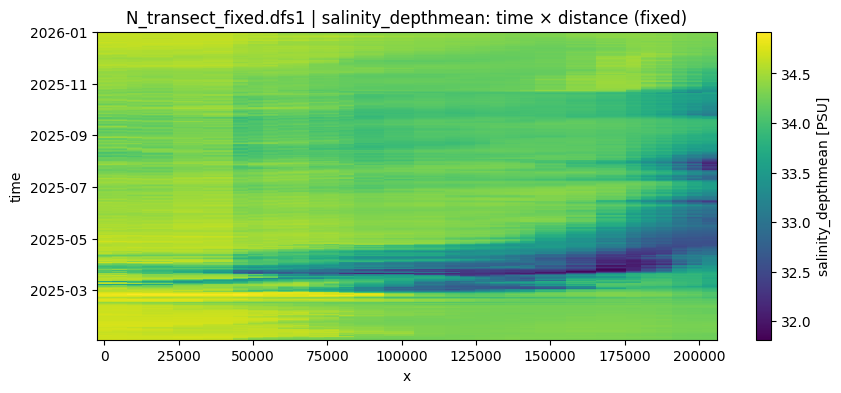

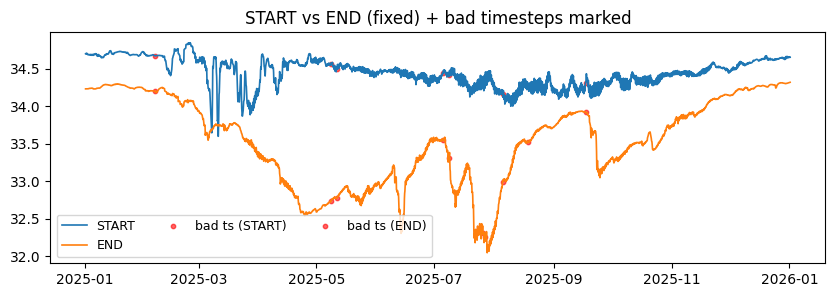


--- Visual check: NE ---


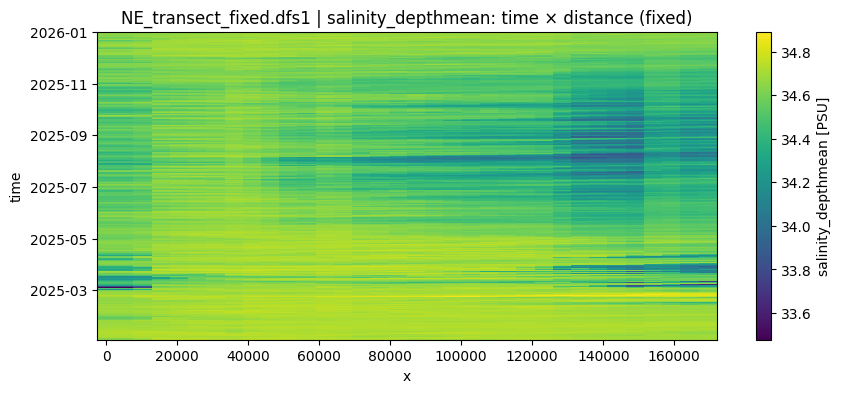

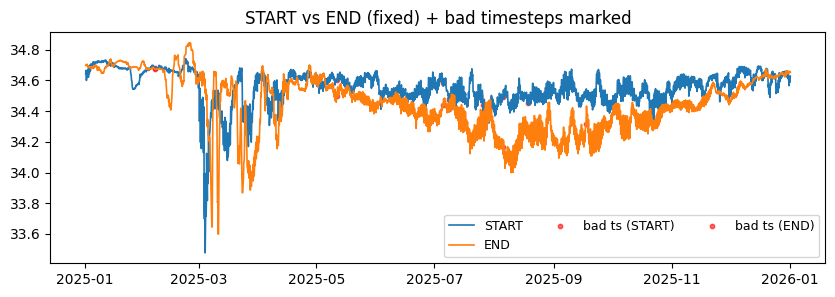


--- Visual check: E ---


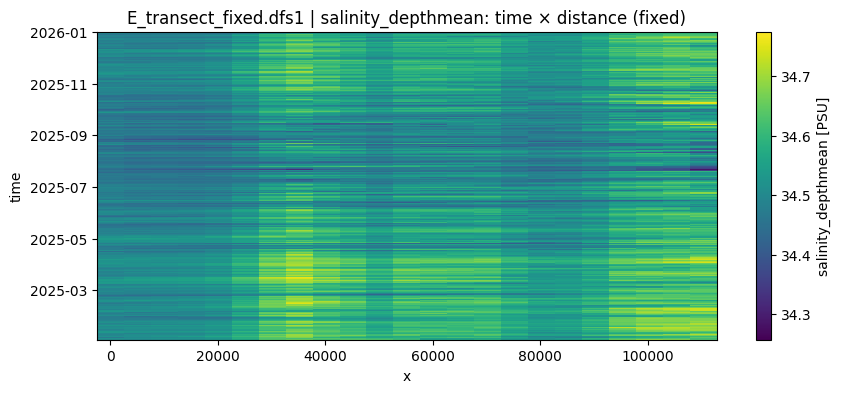

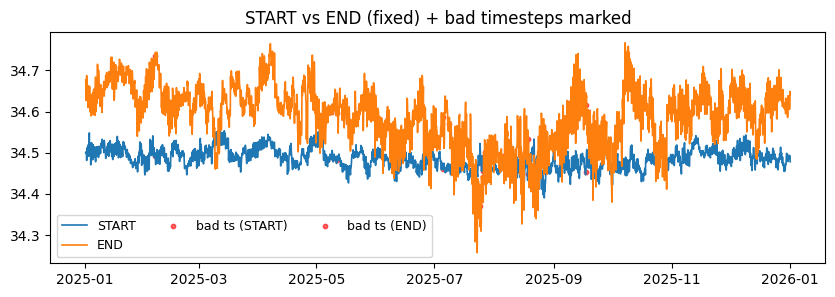


--- Visual check: S ---


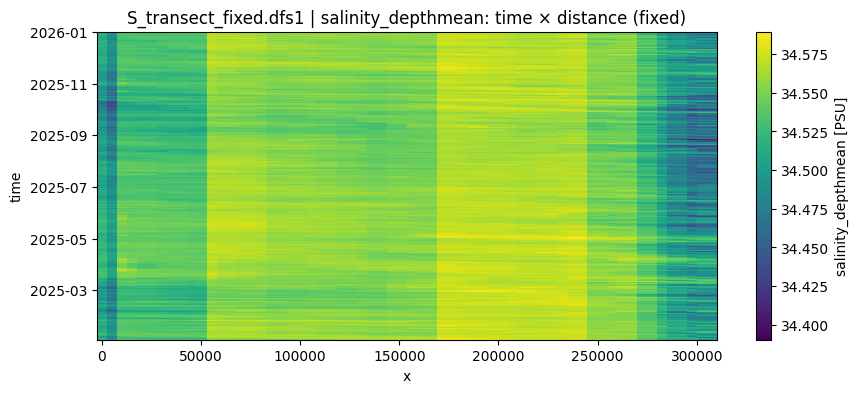

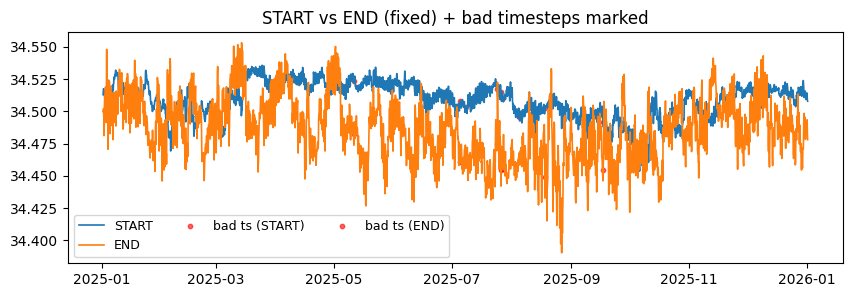


--- Visual check: SW ---


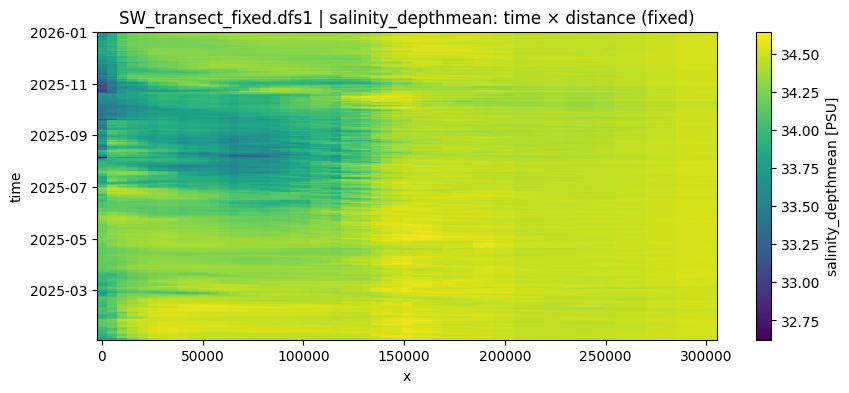

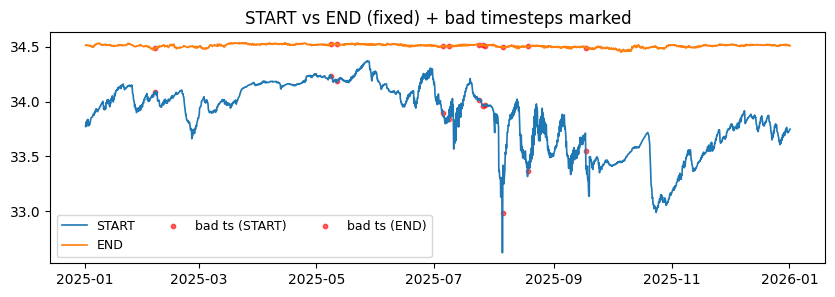

In [10]:
def visual_check_one(dfs1_path, item_name, bad_mask):
    ds = mikeio.read(dfs1_path)
    da = pick_item(ds, item_name)
    t = pd.DatetimeIndex(ds.time)

    # 1) time × distance 热图
    fig, ax = plt.subplots(1, 1, figsize=(10, 4))
    da.plot(ax=ax)
    ax.set_title(f"{os.path.basename(dfs1_path)} | {da.name}: time × distance (fixed)")
    plt.show()

    # 2) START vs END
    A = np.where(np.isfinite(da.to_numpy()), da.to_numpy(), np.nan)
    y0 = A[:, 0]
    y1 = A[:, -1]

    fig, ax = plt.subplots(1, 1, figsize=(10, 3))
    ax.plot(t, y0, lw=1.2, label="START")
    ax.plot(t, y1, lw=1.2, label="END")

    bt = t[np.asarray(bad_mask, dtype=bool)]
    ax.scatter(bt, y0[np.asarray(bad_mask, dtype=bool)], s=10, c="r", alpha=0.6, label="bad ts (START)")
    ax.scatter(bt, y1[np.asarray(bad_mask, dtype=bool)], s=10, c="r", alpha=0.6, label="bad ts (END)")

    ax.set_title("START vs END (fixed) + bad timesteps marked")
    ax.legend(ncol=3, fontsize=9)
    plt.show()

for bnd in boundaries:
    name = bnd["name"]
    dfs1_path = os.path.join(out_dir, f"{name}_transect_fixed.dfs1")
    print("\n--- Visual check:", name, "---")
    visual_check_one(dfs1_path, plot_item_name, bad_mask)

# 2D Water Temp

In [31]:
# ========= 输入 =========
in_dfs2 = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\water_temp_depthmean.dfs2"          # TODO: 你的源 dfs2（同一个）
out_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc"       # TODO: 输出文件夹（会自动生成文件名）

# ========= 输出：坏时间步清单 =========
bad_csv = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\bad_timesteps.csv"

# ========= QC 只做一次，用哪个边界做 QC =========
qc_boundary_index = 0             # 默认用 N 做 QC（也可以改成 2/3/4/5）

# ========= QC 阈值（按你的图：横向异常带 + 端点尖刺）=========
target_T = 20.0        
near20_thr = 1.0       
nan_frac_thr = 0.30    
flat_range_fix = 0.4   
flat_mad_fix   = 0.15
# 设定时间窗口大小（假设数据是逐日，5或7代表参考前后几天的均态，推荐奇数）
rolling_window = 5     
# 设定允许的最大突变温度差（℃）。海洋大面积中位数在几天内突变超过 1.5℃ 极不寻常
time_jump_thr = 1.5

ds2 = mikeio.read(in_dfs2)  # 只读一次
print(ds2)
print("projection:", ds2.geometry.projection)

<mikeio.Dataset>
dims: (time:2920, y:177, x:89)
time: 2025-01-01 12:00:00 - 2026-01-01 09:00:00 (2920 records)
geometry: Grid2D (ny=177, nx=89)
items:
  0:  water_temp_depthmean <Temperature> (degree Celsius)
projection: LONG/LAT


In [32]:
wet_score = compute_wet_score(ds2, qc_item_name)

qc_bnd = boundaries[qc_boundary_index]
ds_qc, pts_qc = extract_transect_nearestcell(
    ds2, qc_bnd["start"], qc_bnd["end"], spacing_m, wet_score, max_radius_cells=max_radius_cells
)


# ---- QC 指标：只抓“全域接近20℃ + 空间很平” ----
da_qc = pick_item(ds_qc, qc_item_name)
A = da_qc.to_numpy()                    # (time, x)
t = pd.DatetimeIndex(ds_qc.time)
A_nan = np.where(np.isfinite(A), A, np.nan)

# 1) 缺测比例
nan_frac = np.mean(~np.isfinite(A), axis=1)
valid_frac = 1.0 - nan_frac

# 2) 空间统计（稳健）
med_x = np.nanmedian(A_nan, axis=1)
p05 = np.nanpercentile(A_nan, 5, axis=1)
p95 = np.nanpercentile(A_nan, 95, axis=1)
range_x = p95 - p05
mad_x = np.nanmedian(np.abs(A_nan - med_x[:, None]), axis=1)

# 3) 自适应“很平”阈值
range_q = np.nanquantile(range_x, 0.02)
mad_q   = np.nanquantile(mad_x,   0.02)
flat_range_thr = max(flat_range_fix, range_q)
flat_mad_thr   = max(flat_mad_fix,   mad_q)

# 【新增】 4) 时间维度突变统计
med_x_series = pd.Series(med_x)
# 计算滑动中位数作为"平滑基准线" (min_periods=1 防止首尾数据变成NaN)
rolling_baseline = med_x_series.rolling(window=rolling_window, center=True, min_periods=1).median()
# 计算当前时间步偏离基准线的绝对值
time_diff = np.abs(med_x_series - rolling_baseline)

# 5) 核心判据
is_near20 = np.abs(med_x - target_T) <= near20_thr
is_flat   = (range_x <= flat_range_thr) | (mad_x <= flat_mad_thr)

# 【新增】 判断是否为时间维度上的突变跳跃点
is_time_jump = time_diff > time_jump_thr

# 最终坏场掩码：缺测过多 OR (空间像20度平场) OR (时间轴上突变)
bad_mask = (
    (nan_frac > nan_frac_thr) |
    ((valid_frac > (1 - nan_frac_thr)) & is_near20 & is_flat) |
    is_time_jump
)

# ---- 输出 QC 表 ----
qc_table = pd.DataFrame({
    "time": t,
    "nan_frac": nan_frac,
    "valid_frac": valid_frac,
    "med_x": med_x,
    "p05": p05,
    "p95": p95,
    "range_x(p95-p05)": range_x,
    "mad_x": mad_x,
    "is_near20": is_near20,
    "is_flat": is_flat,
    "time_diff": time_diff,         # 【新增】偏离基准线的值，方便你复盘
    "is_time_jump": is_time_jump,   # 【新增】是否被判定为突变
    "is_bad": bad_mask
})

qc_table.loc[qc_table["is_bad"]].to_csv(bad_csv, index=False)
print("Bad timesteps:", int(bad_mask.sum()), "/", len(bad_mask))
print("Saved bad list:", bad_csv)

# 打印时加上新列，方便你观察那些被时间突变抓住的漏网之鱼
display(qc_table.loc[qc_table["is_bad"],
        ["time", "nan_frac", "med_x", "range_x(p95-p05)", "is_flat", "time_diff", "is_time_jump"]].head(50))

# 点位映射表照旧
pts_qc.to_csv(os.path.join(out_dir, f"{qc_bnd['name']}_points_used.csv"), index=False)
print("Saved points_used:", os.path.join(out_dir, f"{qc_bnd['name']}_points_used.csv"))

Bad timesteps: 57 / 2920
Saved bad list: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\bad_timesteps.csv


,time,nan_frac,med_x,range_x(p95-p05),is_flat,time_diff,is_time_jump
99,2025-01-13 21:00:00,0.0,19.919416,0.124788,True,3.904171,True
115,2025-01-15 21:00:00,0.0,19.943518,0.054552,True,3.997941,True
119,2025-01-16 09:00:00,0.0,19.946163,0.056393,True,3.784386,True
127,2025-01-17 09:00:00,0.0,19.941437,0.096684,True,4.416483,True
131,2025-01-17 21:00:00,0.0,19.932899,0.104052,True,4.521907,True
135,2025-01-18 09:00:00,0.0,19.980515,0.048681,True,4.564591,True
139,2025-01-18 21:00:00,0.0,19.994778,0.011538,True,4.749040,True
143,2025-01-19 09:00:00,0.0,19.930603,0.085360,True,4.843410,True
147,2025-01-19 21:00:00,0.0,19.908785,0.102285,True,5.042608,True
151,2025-01-20 09:00:00,0.0,19.943443,0.073460,True,4.801328,True


Saved points_used: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\N_points_used.csv


In [33]:
for bnd in boundaries:
    name = bnd["name"]
    print("\n==== Processing", name, "====")

    ds_tx, pts = extract_transect_nearestcell(
        ds2, bnd["start"], bnd["end"], spacing_m, wet_score, max_radius_cells=max_radius_cells
    )

    # 保存“使用的点位”（含吸附后 lon/lat、wet_score）
    pts_csv = os.path.join(out_dir, f"{name}_points_used.csv")
    pts.to_csv(pts_csv, index=False)

    # 时间修复坏步（统一 bad_mask）
    ds_fix = fix_transect_dataset(ds_tx, bad_mask, fill_edges=fill_edges_with_nearest)

    # 输出 dfs1
    out_dfs1 = os.path.join(out_dir, f"{name}_transect_fixed.dfs1")
    ds_fix.to_dfs(out_dfs1)  # dfs1 写法【7-be9eb2】

    print("Written:", out_dfs1)
    print("Points :", pts_csv)


==== Processing N ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\N_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\N_points_used.csv

==== Processing NE ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\NE_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\NE_points_used.csv

==== Processing E ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\E_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\E_points_used.csv

==== Processing S ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\S_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\S_points_used.csv

==== Processing SW ====
Written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\SW_transect_fixed.dfs1
Points : C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\SW_points_used.csv



--- Visual check: N ---


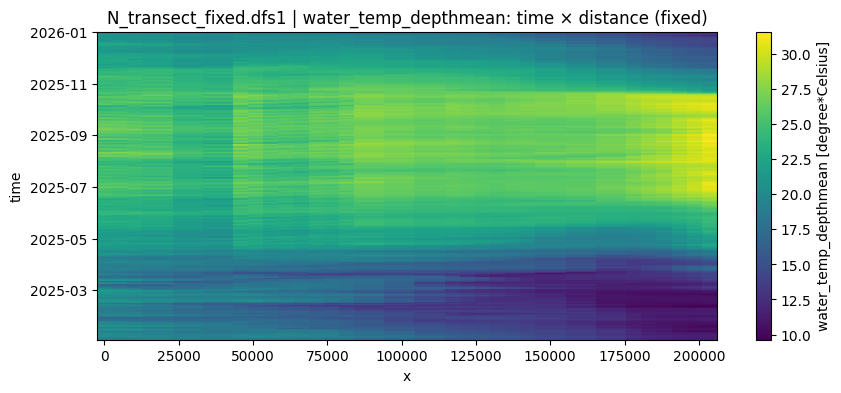

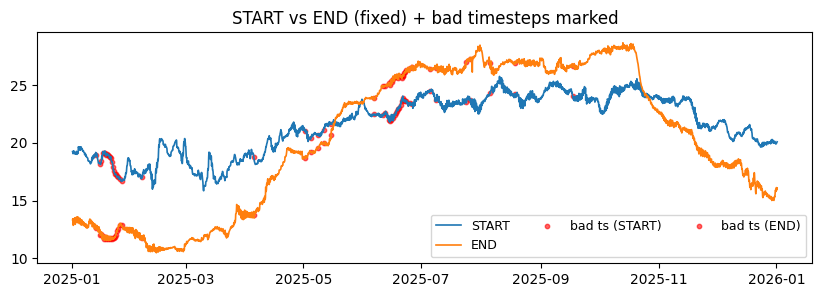


--- Visual check: NE ---


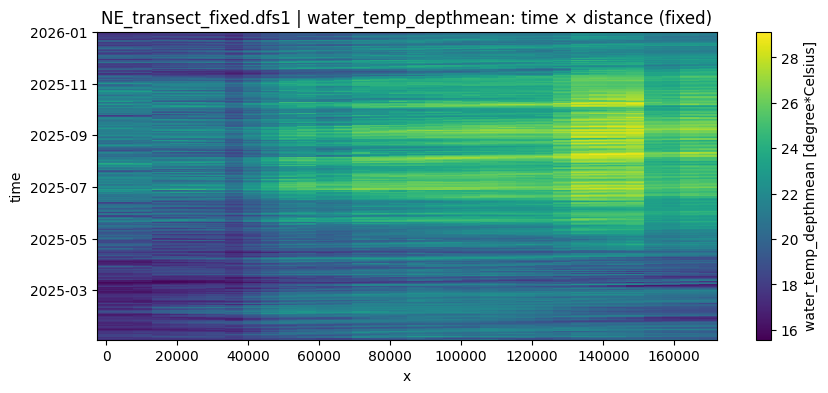

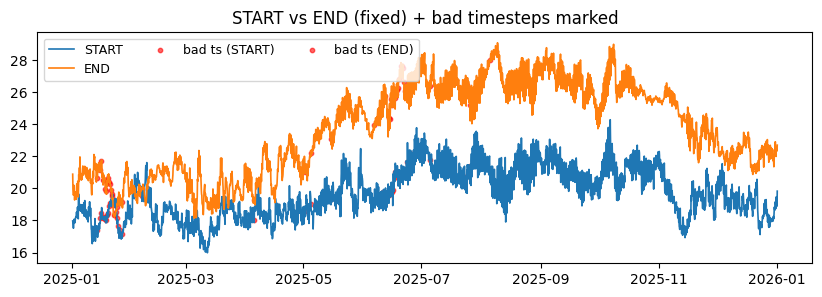


--- Visual check: E ---


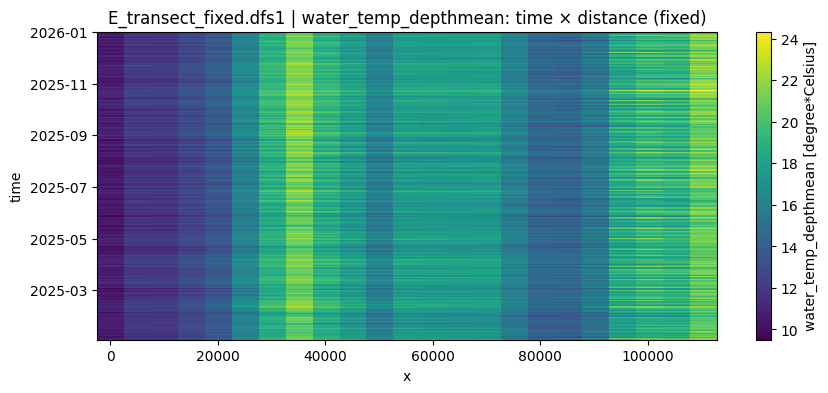

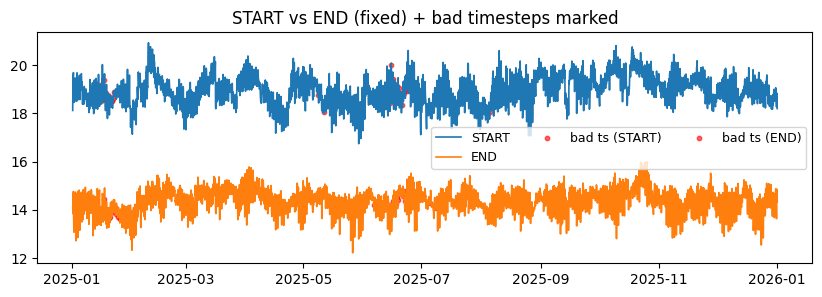


--- Visual check: S ---


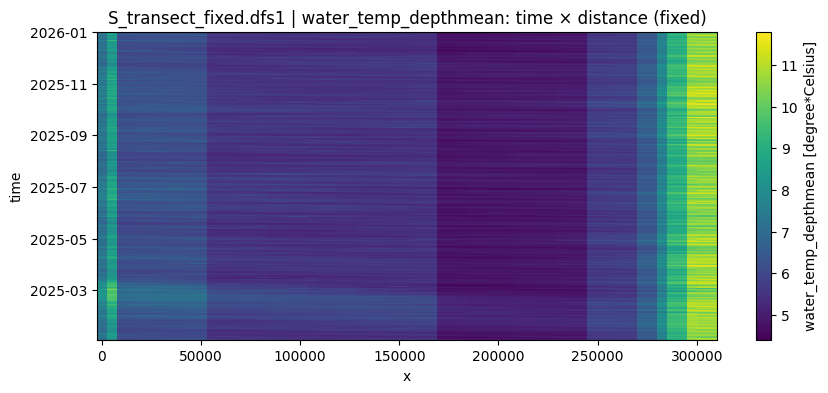

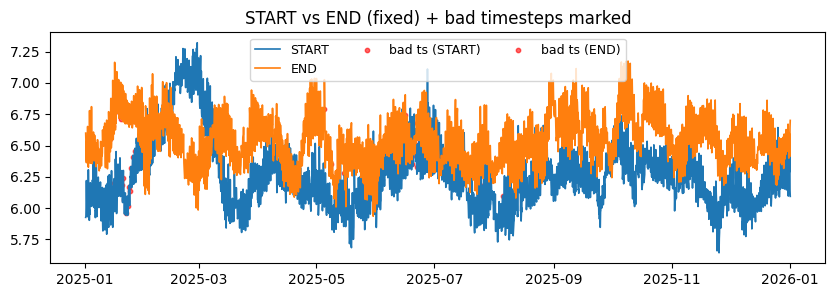


--- Visual check: SW ---


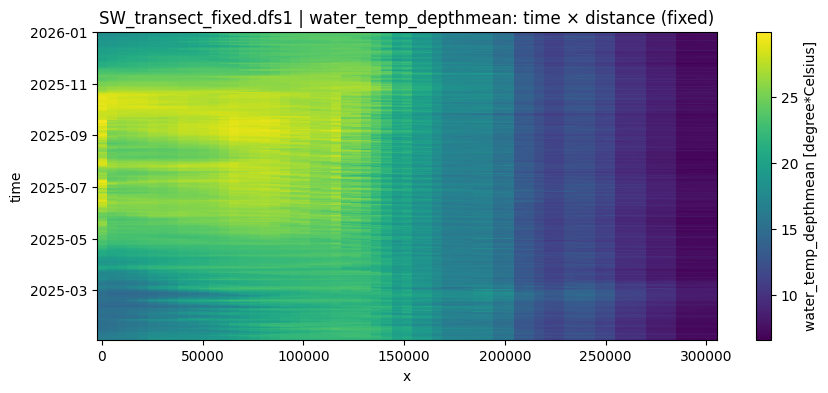

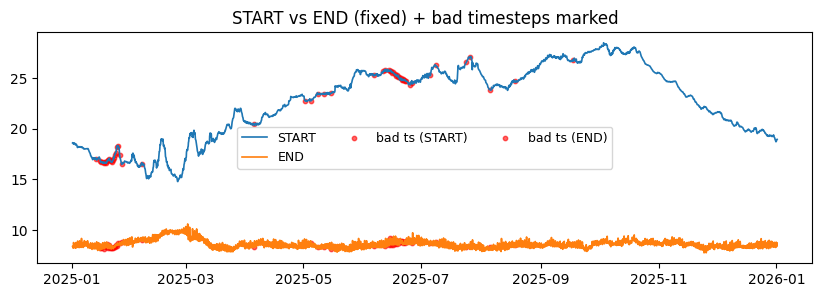

In [ ]:
def visual_check_one(dfs1_path, item_name, bad_mask):
    ds = mikeio.read(dfs1_path)
    da = pick_item(ds, item_name)
    t = pd.DatetimeIndex(ds.time)

    # 1) time × distance 热图
    fig, ax = plt.subplots(1, 1, figsize=(10, 4))
    da.plot(ax=ax)
    ax.set_title(f"{os.path.basename(dfs1_path)} | {da.name}: time × distance (fixed)")
    plt.show()

    # 2) START vs END
    A = np.where(np.isfinite(da.to_numpy()), da.to_numpy(), np.nan)
    y0 = A[:, 6]
    y1 = A[:, -7]

    fig, ax = plt.subplots(1, 1, figsize=(10, 3))
    ax.plot(t, y0, lw=1.2, label="START")
    ax.plot(t, y1, lw=1.2, label="END")

    bt = t[np.asarray(bad_mask, dtype=bool)]
    ax.scatter(bt, y0[np.asarray(bad_mask, dtype=bool)], s=10, c="r", alpha=0.6, label="bad ts (START)")
    ax.scatter(bt, y1[np.asarray(bad_mask, dtype=bool)], s=10, c="r", alpha=0.6, label="bad ts (END)")

    ax.set_title("START vs END (fixed) + bad timesteps marked")
    ax.legend(ncol=3, fontsize=9)
    plt.show()

for bnd in boundaries:
    name = bnd["name"]
    dfs1_path = os.path.join(out_dir, f"{name}_transect_fixed.dfs1")
    print("\n--- Visual check:", name, "---")
    visual_check_one(dfs1_path, plot_item_name, bad_mask)